<a href="https://colab.research.google.com/github/Hamees123/Roman_Urdu_Hate_Speech_Model/blob/main/Roman_Urdu_Hate_Speech_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers datasets accelerate scikit-learn \
    pandas numpy matplotlib seaborn gradio

In [ ]:
import os
import subprocess

REPO_URL = "https://github.com/Bilal4209/RU-HSD-30K.git"
REPO_DIR = "/content/RU-HSD-30K"

if not os.path.exists(REPO_DIR):
    subprocess.run(
        ["git", "clone", REPO_URL, REPO_DIR],
        check=True
    )

print("Repository files:")

for root, dirs, files in os.walk(REPO_DIR):
    dirs[:] = [
        d for d in dirs
        if d not in [".git"]
    ]

    for filename in files:
        print(os.path.join(root, filename))

Repository files:
/content/RU-HSD-30K/final 30,000 dataset_romanurdu.csv


In [ ]:
import pandas as pd
import os

supported_extensions = (
    ".csv", ".tsv", ".txt", ".xlsx"
)

data_files = []

for root, dirs, files in os.walk(REPO_DIR):
    dirs[:] = [d for d in dirs if d != ".git"]

    for filename in files:
        if filename.lower().endswith(supported_extensions):
            data_files.append(
                os.path.join(root, filename)
            )

print("Tabular files found:")
for i, path in enumerate(data_files):
    print(i, path)

Tabular files found:
0 /content/RU-HSD-30K/final 30,000 dataset_romanurdu.csv


In [ ]:
import pandas as pd

file_path = "/content/RU-HSD-30K/final 30,000 dataset_romanurdu.csv"

encodings = ["cp1252", "latin1", "ISO-8859-1"]

for encoding in encodings:
    try:
        df = pd.read_csv(file_path, encoding=encoding)
        print("Successfully loaded dataset using:", encoding)
        break
    except UnicodeDecodeError:
        print("Failed with encoding:", encoding)

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))

Failed with encoding: cp1252
Successfully loaded dataset using: latin1

Dataset shape: (30000, 2)

Column names:
['tweets', 'label']

First 10 rows:


,tweets,label
0,14 crore ke project ko banaa ke 14 arab khaa ...,H
1,Abhi bari hojao phir siyasat ki baat karna,H
2,Allah aap ko sehat zindagi dy taky aap choron...,H
3,antiii bhaii full gussy m h,H
4,Beshak bahar se parh ke aaya ho lekin bilawal...,H
5,"hum hai fb Jemee Usman kay king hum se, pang...",H
6,Imran khan ney kiya kiya apnay national telev...,H
7,inka sar oraya jaye dosra asla par pabandi la...,H
8,lahoriiii burger Soja beta apka time hogya. S...,H
9,Lannat beshamarGo Qamar Bajwa goGo cheap just...,H


In [ ]:
# Count the examples in each label category
print("Label counts:")
print(df["label"].value_counts(dropna=False))

print("\nLabel percentages:")
print((df["label"].value_counts(normalize=True, dropna=False) * 100).round(2))

print("\nUnique labels:")
print(df["label"].unique())

Label counts:
label
N    15199
H    14801
Name: count, dtype: int64

Label percentages:
label
N    50.66
H    49.34
Name: proportion, dtype: float64

Unique labels:
['H' 'N']


In [ ]:

import pandas as pd

# Load the dataset using the encoding that worked
file_path = "/content/RU-HSD-30K/final 30,000 dataset_romanurdu.csv"
df = pd.read_csv(file_path, encoding="latin1")

# Remove rows with missing text or labels
df = df.dropna(subset=["tweets", "label"]).copy()

# Remove leading/trailing spaces
df["tweets"] = df["tweets"].astype(str).str.strip()
df["label"] = df["label"].astype(str).str.strip().str.upper()

# Remove empty tweets
df = df[df["tweets"] != ""]

# Keep only the expected labels
df = df[df["label"].isin(["H", "N"])].copy()

# Remove exact duplicate text entries
df = df.drop_duplicates(subset=["tweets"]).reset_index(drop=True)

# Convert labels to numbers:
# 0 = Non-Hate, 1 = Hate
df["label_id"] = df["label"].map({"N": 0, "H": 1})

print("Cleaned dataset shape:", df.shape)
print("\nLabel counts:")
print(df["label"].value_counts())
print("\nSample records:")
display(df.head())


Cleaned dataset shape: (29804, 3)

Label counts:
label
N    15067
H    14737
Name: count, dtype: int64

Sample records:


,tweets,label,label_id
0,14 crore ke project ko banaa ke 14 arab khaa g...,H,1
1,Abhi bari hojao phir siyasat ki baat karna,H,1
2,Allah aap ko sehat zindagi dy taky aap choron ...,H,1
3,antiii bhaii full gussy m h,H,1
4,Beshak bahar se parh ke aaya ho lekin bilawal ...,H,1


In [ ]:
total_tokens = sum(len(tokenizer.encode(str(tweet))) for tweet in df['tweets'])
print(f"Total tokens generated from the dataset: {total_tokens:,}")
print(f"Average tokens per tweet: {total_tokens / len(df):.2f}")

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (574 > 512). Running this sequence through the model will result in indexing errors


Total tokens generated from the dataset: 783,964
Average tokens per tweet: 26.30


In [ ]:

from sklearn.model_selection import train_test_split

# First, separate 10% for final testing
train_val_df, test_df = train_test_split(
    df,
    test_size=0.10,
    random_state=42,
    stratify=df["label_id"]
)

# Split the remaining 90% into training and validation
train_df, val_df = train_test_split(
    train_val_df,
    test_size=1/9,
    random_state=42,
    stratify=train_val_df["label_id"]
)

print("Training examples:", len(train_df))
print("Validation examples:", len(val_df))
print("Testing examples:", len(test_df))

print("\nTraining label distribution:")
print(train_df["label"].value_counts())

print("\nValidation label distribution:")
print(val_df["label"].value_counts())

print("\nTesting label distribution:")
print(test_df["label"].value_counts())


Training examples: 23842
Validation examples: 2981
Testing examples: 2981

Training label distribution:
label
N    12053
H    11789
Name: count, dtype: int64

Validation label distribution:
label
N    1507
H    1474
Name: count, dtype: int64

Testing label distribution:
label
N    1507
H    1474
Name: count, dtype: int64


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={0: "Non-Hate", 1: "Hate"},
    label2id={"Non-Hate": 0, "Hate": 1}
)

print("Model loaded successfully!")
print("GPU available:", torch.cuda.is_available())

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully!
GPU available: True


In [ ]:
from datasets import Dataset

def convert_to_dataset(frame):
    data = Dataset.from_pandas(
        frame[["tweets", "label_id"]].rename(
            columns={"label_id": "labels"}
        ).reset_index(drop=True)
    )

    return data

train_ds = convert_to_dataset(train_df)
val_ds = convert_to_dataset(val_df)
test_ds = convert_to_dataset(test_df)

def tokenize_function(batch):
    return tokenizer(
        batch["tweets"],
        truncation=True,
        max_length=128
    )

train_ds = train_ds.map(tokenize_function, batched=True)
val_ds = val_ds.map(tokenize_function, batched=True)
test_ds = test_ds.map(tokenize_function, batched=True)

train_ds = train_ds.remove_columns(["tweets"])
val_ds = val_ds.remove_columns(["tweets"])
test_ds = test_ds.remove_columns(["tweets"])

print(train_ds[0])

Map:   0%|          | 0/23842 [00:00<?, ? examples/s]

Map:   0%|          | 0/2981 [00:00<?, ? examples/s]

Map:   0%|          | 0/2981 [00:00<?, ? examples/s]

{'labels': 0, 'input_ids': [0, 108583, 35422, 2], 'attention_mask': [1, 1, 1, 1]}


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import (
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision_hate": precision,
        "recall_hate": recall,
        "f1_hate": f1
    }

training_args = TrainingArguments(
    output_dir="/content/roman_urdu_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1_hate",
    report_to="none",
    fp16=torch.cuda.is_available()
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics
)

print("Training setup complete!")

Training setup complete!


In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision Hate,Recall Hate,F1 Hate
1,0.409553,0.294093,0.874874,0.883090,0.860923,0.871865
2,0.343519,0.327103,0.886280,0.881128,0.890095,0.885589
3,0.301178,0.435385,0.893995,0.887550,0.899593,0.893531


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=8943, training_loss=0.3808405058343685, metrics={'train_runtime': 1060.4693, 'train_samples_per_second': 67.447, 'train_steps_per_second': 8.433, 'total_flos': 2234689554265080.0, 'train_loss': 0.3808405058343685, 'epoch': 3.0})

In [ ]:
# Evaluate the model on unseen test data
test_results = trainer.evaluate(test_ds)

print("Test Results:")
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}" if isinstance(value, (int, float)) else f"{metric}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision Hate,Recall Hate,F1 Hate
0.301178,0.513513,3,0.878900,0.867327,0.891452,0.879224


Test Results:
eval_loss: 0.5135
eval_accuracy: 0.8789
eval_precision_hate: 0.8673
eval_recall_hate: 0.8915
eval_f1_hate: 0.8792


              precision    recall  f1-score   support

    Non-Hate       0.89      0.87      0.88      1507
        Hate       0.87      0.89      0.88      1474

    accuracy                           0.88      2981
   macro avg       0.88      0.88      0.88      2981
weighted avg       0.88      0.88      0.88      2981



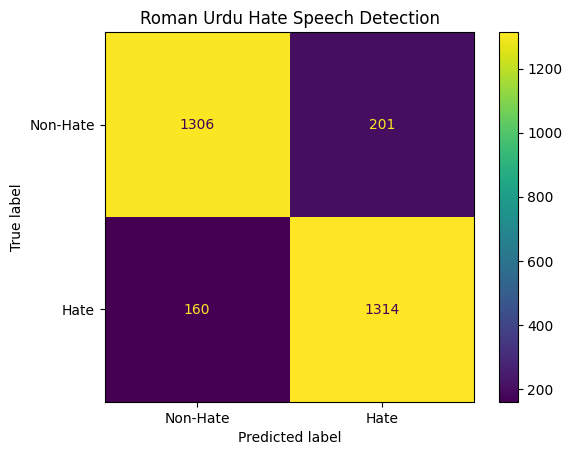

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict labels for the test dataset
predictions_output = trainer.predict(test_ds)

y_true = predictions_output.label_ids
y_pred = np.argmax(predictions_output.predictions, axis=1)

# Detailed performance report
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Non-Hate", "Hate"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Hate", "Hate"]
)

display.plot()
plt.title("Roman Urdu Hate Speech Detection")
plt.show()

In [ ]:
import torch

def detect_hate_speech(text):
    model = trainer.model
    model.eval()

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    # Move inputs to the same device as the model
    device = next(model.parameters()).device
    inputs = {key: value.to(device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(outputs.logits, dim=1)[0]

    predicted_id = int(torch.argmax(probabilities).item())

    labels = {0: "Non-Hate", 1: "Hate"}

    return {
        "text": text,
        "prediction": labels[predicted_id],
        "confidence": round(float(probabilities[predicted_id].item()) * 100, 2)
    }

# Try a sample sentence
result = detect_hate_speech("Tumhari baat se main bilkul agree nahi karta")
print(result)

{'text': 'Tumhari baat se main bilkul agree nahi karta', 'prediction': 'Non-Hate', 'confidence': 99.33}


In [ ]:
save_path = "/content/drive/MyDrive/roman_urdu_hate_speech/roman_urdu_hate_model"

trainer.save_model(save_path)
tokenizer.save_pretrained(save_path)

print("Model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!


In [ ]:
!pip install -q gradio

In [ ]:

import torch
import gradio as gr

# Use the trained model from your existing notebook
model = trainer.model
model.eval()

device = next(model.parameters()).device

def predict_hate_speech(text):
    if not text or not text.strip():
        return "Please enter some Roman Urdu text.", {}

    inputs = tokenizer(
        text.strip(),
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.no_grad():
        outputs = model(**inputs)
        probabilities = torch.softmax(
            outputs.logits, dim=-1
        )[0]

    # Your training mapping: 0 = Non-Hate, 1 = Hate
    scores = {
        "Non-Hate": float(probabilities[0].item()),
        "Hate": float(probabilities[1].item())
    }

    predicted_label = max(scores, key=scores.get)
    confidence = scores[predicted_label] * 100

    result = (
        f"Prediction: {predicted_label}\n"
        f"Confidence: {confidence:.2f}%"
    )

    return result, scores


# Build the interface
with gr.Blocks(theme=gr.themes.Soft(), title="Roman Urdu Hate Speech Detector") as demo:

    gr.Markdown(
        """
        # Roman Urdu Hate Speech Detector
        ### AI-powered text classification using fine-tuned XLM-RoBERTa

        Enter Roman Urdu text to check whether the model classifies
        it as Hate or Non-Hate.
        """
    )

    with gr.Row():
        with gr.Column():
            text_input = gr.Textbox(
                label="Enter Roman Urdu Text",
                placeholder="Misal: Tum bohat achay insan ho...",
                lines=5,
                max_lines=8
            )

            analyze_button = gr.Button(
                "Analyze Text",
                variant="primary"
            )

            gr.Examples(
                examples=[
                    ["Tum bohat achay insan ho"],
                    ["Main tumhari baat se agree nahi karta"],
                    ["Mujhe yeh faisla bilkul pasand nahi"]
                ],
                inputs=text_input
            )

        with gr.Column():
            result_output = gr.Textbox(
                label="Prediction",
                lines=3,
                interactive=False
            )

            score_output = gr.Label(
                label="Class Probabilities",
                num_top_classes=2
            )

    analyze_button.click(
        fn=predict_hate_speech,
        inputs=text_input,
        outputs=[result_output, score_output]
    )

    text_input.submit(
        fn=predict_hate_speech,
        inputs=text_input,
        outputs=[result_output, score_output]
    )

    gr.Markdown(
        """
        **Disclaimer:** Predictions are automated and may be incorrect.
        The model is a research prototype, not a definitive judge of
        harmful language. Its reliability depends on its training data.
        """
    )

demo.launch(share=True)


NameError: name 'trainer' is not defined

In [ ]:
from google.colab import drive
from transformers import AutoModelForSequenceClassification, AutoTokenizer
import torch

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Path where you saved your model
model_path = "/content/drive/MyDrive/roman_urdu_hate_speech/roman_urdu_hate_model"

# 3. Load the saved tokenizer and model
tokenizer = AutoTokenizer.from_pretrained(model_path)
model = AutoModelForSequenceClassification.from_pretrained(model_path)

# 4. Set model to evaluation mode and use GPU if available
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)
model.eval()

print("Model and tokenizer loaded successfully!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model and tokenizer loaded successfully!


In [ ]:
from transformers import pipeline

classifier = pipeline(
    "text-classification",
    model="/content/drive/MyDrive/roman_urdu_hate_speech/roman_urdu_hate_model",
    tokenizer="/content/drive/MyDrive/roman_urdu_hate_speech/roman_urdu_hate_model",
    device=0 if torch.cuda.is_available() else -1
)

result = classifier("apka text yahan aye ga")
print(result)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[{'label': 'Non-Hate', 'score': 0.9942763447761536}]


In [ ]:
import gradio as gr
from transformers import pipeline

model_path = "/content/drive/MyDrive/roman_urdu_hate_speech/roman_urdu_hate_model"
classifier = pipeline("text-classification", model=model_path, tokenizer=model_path)

# Define the classification function
def classify_text(text):
    result = classifier(text)[0]
    # Gradio Label component expects a dictionary of {label: confidence_score}
    return {result['label']: result['score']}

# Set up the Gradio interface with custom text inputs and a label output
interface = gr.Interface(
    fn=classify_text,
    inputs=gr.Textbox(lines=2, placeholder="Enter Roman Urdu text here..."),
    outputs=gr.Label(num_top_classes=2),
    title="Roman Urdu Hate Speech Classifier",
    description="Classify Roman Urdu text to detect hate speech.",
)

interface.launch(share=True)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8d706dd728b1a89413.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!pip install huggingface_hub
from huggingface_hub import login

# This prompts for your authentication token in notebook environments
login()

In [ ]:
from huggingface_hub import HfApi, create_repo

repo_name = "Hamees12/roman-urdu-hate-detector"

# 1. Create the empty repository on Hugging Face
create_repo(repo_id=repo_name, repo_type="model", exist_ok=True)

# 2. Upload your model and tokenizer files
api = HfApi()
api.upload_folder(
    folder_path="/content/drive/MyDrive/roman_urdu_hate_speech/roman_urdu_hate_model",
    repo_id=repo_name,
    repo_type="model"
)

CommitInfo(commit_url='https://huggingface.co/Hamees12/roman-urdu-hate-detector/commit/d1bbf2426cac23cf4f9f602d21eceaf224a4d4d4', commit_message='Upload folder using huggingface_hub', commit_description='', oid='d1bbf2426cac23cf4f9f602d21eceaf224a4d4d4', pr_url=None, repo_url=RepoUrl('https://huggingface.co/Hamees12/roman-urdu-hate-detector', endpoint='https://huggingface.co', repo_type='model', repo_id='Hamees12/roman-urdu-hate-detector'), pr_revision=None, pr_num=None)